In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from corner import corner, overplot_lines, overplot_points
from jax import jit
from scipy.stats import qmc
from scipy.stats import t as stuent_t
from raddest.reg.func import saturated_linear
from utils.linear_model import get_ODR, get_OLS, xy2logxy


In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = 10**np.random.normal(0, 0.3, size=N)
x0, x1 = np.percentile(np.log10(x), [5, 95])
c0, c1 = np.percentile(k * np.log10(x) + b, [1, 99])

y = 10**(saturated_linear(np.log10(x), k=k, b=b, x0=x0, x1=x1, c0=c0, c1=c1) +
         np.random.normal(0, sig, size=N))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

Text(0, 0.5, 'log(y)')

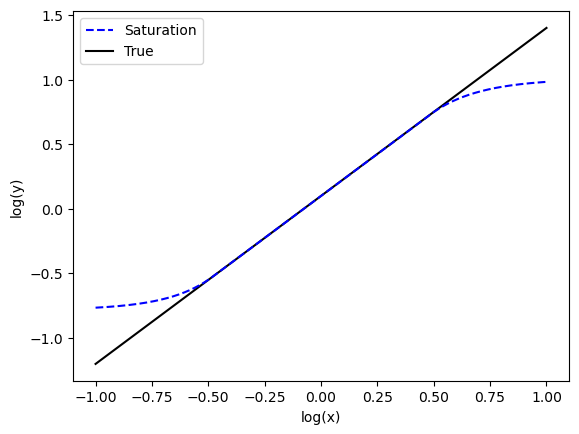

In [ ]:
log_xx = np.linspace(-1, 1, 1000)
log_yy = k * log_xx + b
log_yy_sat = saturated_linear(log_xx, k=k, b=b, x0=x0, x1=x1, c0=c0, c1=c1)
plt.plot(log_xx,
         log_yy_sat,
         color='blue',
         label='Saturation',
         zorder=10,
         linestyle='--')
plt.plot(log_xx, log_yy, color='black', label='True')
plt.legend()
plt.xlabel('log(x)')
plt.ylabel('log(y)')

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:39: RuntimeWarning: invalid value encountered in log10
  logx = np.log10(x)
/work/jingtao/workspace/myrepos/raddest/example/utils/linear_model.py:40: RuntimeWarning: invalid value encountered in log10
  logy = np.log10(y)
2026-11-24 20:51:52.376507: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

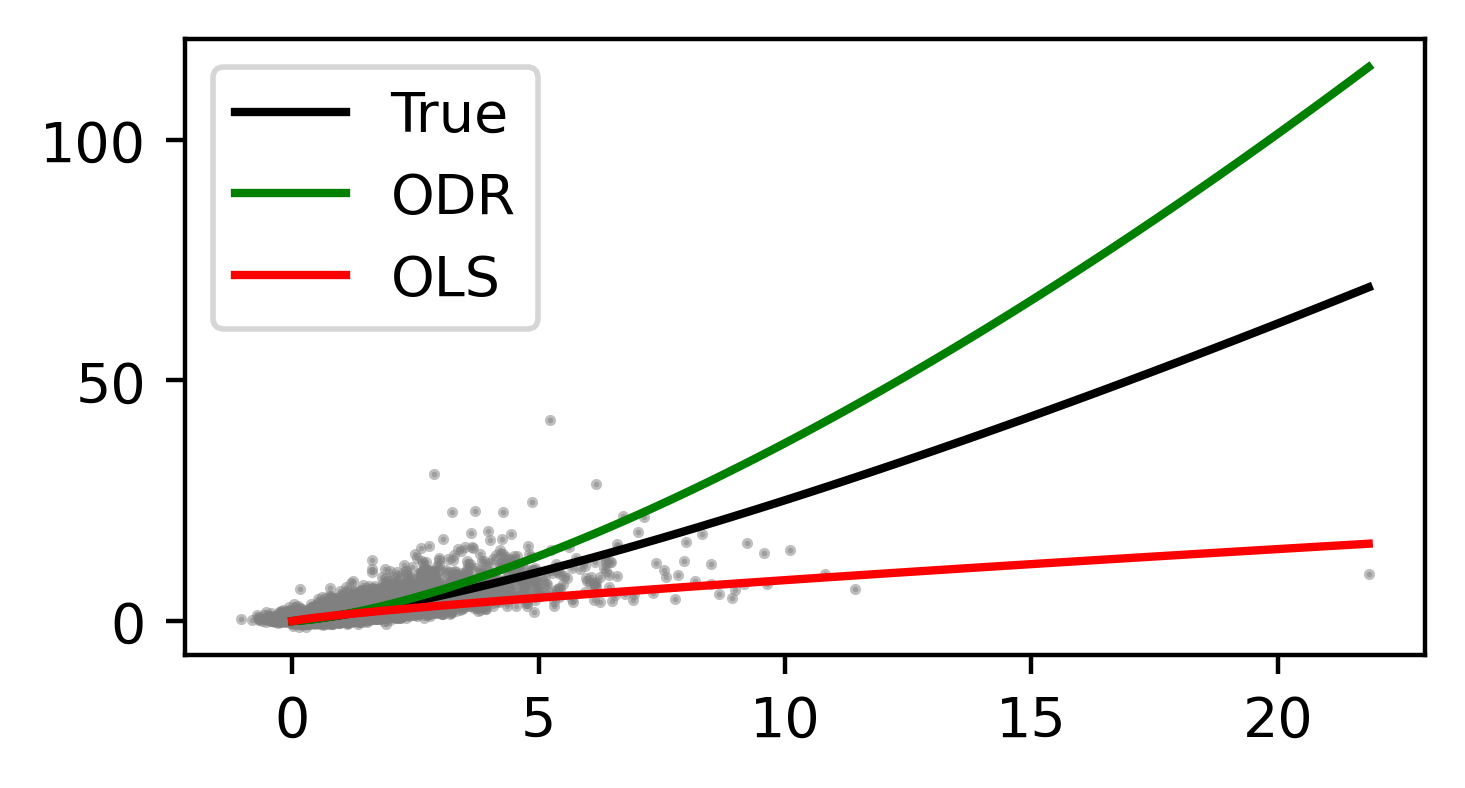

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
# yy_sat = 10**linear_sigmoid(np.log10(xx), k, b, x0, x1, c0, c1)
yy_ODR = 10**res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10**res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from jax.scipy.stats import norm

from raddest.api.fitter import (LogLinearKS, LogLinearML,
                                LogLinearStudentTML, RegressorML)
from raddest.api.flowvi import FlowVI
from raddest.reg.map import get_w_add_lognorm
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:46,  5.93s/it]

  8%|▊         | 8/100 [00:06<00:50,  1.81it/s]

 15%|█▌        | 15/100 [00:06<00:21,  4.02it/s]

 22%|██▏       | 22/100 [00:06<00:11,  6.93it/s]

 29%|██▉       | 29/100 [00:06<00:06, 10.67it/s]

... (11 outputs left out)

step 10: loss 0.3059267997741699
step 20: loss 0.2950649857521057


step 30: loss 0.28849393129348755
step 40: loss 0.2846778333187103


step 50: loss 0.2827775180339813
step 60: loss 0.2813994288444519


step 70: loss 0.28042739629745483


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.016749992966651917, 0.32061643958713276)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

  0%|          | 0/100 [00:00<?, ?it/s]

  1%|          | 1/100 [00:05<09:02,  5.48s/it]

  8%|▊         | 8/100 [00:05<00:47,  1.95it/s]

 15%|█▌        | 15/100 [00:05<00:19,  4.33it/s]

 23%|██▎       | 23/100 [00:05<00:09,  7.87it/s]

 31%|███       | 31/100 [00:05<00:05, 12.36it/s]

... (9 outputs left out)

step 0: loss 0.9303269386291504
step 10: loss 0.8334071040153503


step 20: loss 0.8256999850273132
step 30: loss 0.8205491900444031


step 40: loss 0.8179135322570801
step 50: loss 0.8157260417938232


step 60: loss 0.8138517737388611
step 70: loss 0.8131551742553711


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.016750000417232513, 0.3206148815358524)

### Normal Model

In [ ]:
regressor_logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = regressor_logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0019639 0.006003255 0.11489053 0.0019806358


1000 1.1515378 0.10881163 0.20419739 0.55293566


2000 1.2021722 0.103934415 0.20163845 0.55573547


3000 1.2210377 0.10193215 0.20096268 0.55612445


4000 1.2280798 0.10116107 0.20074856 0.5561786


5000 1.2307125 0.100869566 0.2006738 0.5561862


6000 1.2316971 0.10076009 0.20064661 0.5561872
converged, so stop with 6000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.2316971 0.10076009 0.20064661
Truth: 1.3 0.1 0.2


### T Model

In [ ]:
loglinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = loglinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0005302 0.0020833397 1.9999685 0.1024965 0.33059418


1000 1.1673303 0.114376955 2.0276034 0.12778209 0.52050066


2000 1.2190789 0.10828607 2.0532744 0.1262783 0.52414745


3000 1.2364746 0.10604243 2.0779247 0.12641308 0.52509105


4000 1.2424387 0.10521589 2.1018138 0.12688491 0.52570164


5000 1.2444593 0.10489401 2.125038 0.12743603 0.52624655


... (191 outputs left out)

197000 1.2402366 0.102637745 3.8669865 0.15530819 0.5453833


198000 1.2402271 0.10263432 3.8719933 0.15535778 0.54540896


199000 1.2402174 0.10263089 3.877 0.15540724 0.5454331


200000 1.2402081 0.10262761 3.8818166 0.15545475 0.54545623
converged, so stop with 200000 iterations


In [ ]:
print('ML fitted:', *params_ml_t)
print('Truth:', k, b, sig)

ML fitted: 1.2402081 0.10262761 3.8818166 0.15545475
Truth: 1.3 0.1 0.2


In [ ]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.17709445147668082

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/site-packages/joblib/externals/loky/backend/fork_exec.py:38: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid = os.fork()


----
k: 1.273 +/- 0.115
b: 0.100 +/- 0.010
sig: 0.198 +/- 0.051


----
k: 1.284 +/- 0.105
b: 0.093 +/- 0.022
sig: 0.207 +/- 0.061


----
k: 1.267 +/- 0.095
b: 0.096 +/- 0.023
sig: 0.201 +/- 0.063


----
k: 1.249 +/- 0.096
b: 0.098 +/- 0.023
sig: 0.202 +/- 0.059


----
k: 1.254 +/- 0.098
b: 0.099 +/- 0.023
sig: 0.206 +/- 0.074


... (3 outputs left out)

----
k: 1.269 +/- 0.098
b: 0.093 +/- 0.023
sig: 0.203 +/- 0.064


----
k: 1.275 +/- 0.105
b: 0.097 +/- 0.023
sig: 0.201 +/- 0.069


----
k: 1.288 +/- 0.098
b: 0.092 +/- 0.022
sig: 0.199 +/- 0.066
max iteration reached


[1.27970775 0.09489788 0.19952765] [0.09444363 0.01978117 0.06238327]


### Saturated Log-Linear ML (customized)

In [ ]:
from raddest.reg.func import saturated_linear_smooth
from raddest.reg.func_jax import saturated_linear_smooth_jax

In [ ]:
def saturated_loglinear_scatter(x, params):
    params_loglinear = params[:-1]
    sig = params[-1]
    k, b, x0, x1, c0, c1 = params_loglinear
    log10_y_pred = saturated_linear_smooth(np.log10(x),
                                           k=k, b=b, x0=x0, x1=x1, c0=c0, c1=c1,
                                           width=0.01)
    return np.power(10,
                    log10_y_pred + np.random.normal(scale=sig, size=x.shape))


@jit
def saturated_loglinear_jax(x, params):
    '''
    params: (k, b, x0, x1, c0, c1)
    '''
    k, b, x0, x1, c0, c1 = params
    log10_y_pred = saturated_linear_smooth_jax(jnp.log10(jnp.abs(x)),
                                               k=k, b=b, x0=x0, x1=x1, c0=c0, c1=c1,
                                               width=0.1)
    return log10_y_pred


@jit
def lognorm(x, y, params):
    return jnp.where((x < 0) | (y < 0), 0,
                     norm.pdf(jnp.log10(jnp.abs(y)),
                              loc=saturated_loglinear_jax(x, params[:-1]),
                              scale=params[-1]))


def construct_saturated_linear_step(d_log_likelihood):

    @jit
    def step(params, x_ext, y_ext, w, lr=1e-3):
        dparams = d_log_likelihood(params, x_ext, y_ext, w)[0]
        k, b, x0, x1, c0, c1, sig = params
        dk, db, dx0, dx1, dc0, dc1, dsig = dparams

        k = jnp.clip(k + lr * dk, -1e2, 1e2)
        b = jnp.clip(b + lr * db, -1e2, 1e2)
        x0 = jnp.clip(x0 + lr * dx0, -1e2, 1e2)
        x1 = jnp.clip(x1 + lr * dx1, -1e2, 1e2)
        c0 = jnp.clip(c0 + lr * dc0, -1e2, 1e2)
        c1 = jnp.clip(c1 + lr * dc1, -1e2, 1e2)

        sig = jnp.clip(sig + lr * dsig, 1e-2, 1e2)
        return (k, b, x0, x1, c0, c1, sig)

    return step


def log_prior(params):
    return jnp.where(params[-1] <= 0, -jnp.inf, 0)


saturated_loglinear_regressor_c = RegressorML(
    xflow,
    yflow,
    p_cond=lognorm,
    step_constructor=construct_saturated_linear_step,
    get_w_add=get_w_add_lognorm,
    func_x2y=saturated_loglinear_scatter,
    log_prior=log_prior)

In [ ]:
params_ml_saturated_c, params_std_saturated_c, cov_saturated_c = saturated_loglinear_regressor_c.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[
        1., 0.,
        np.log10(np.percentile(x_obs, 5)),
        np.log10(np.percentile(x_obs, 95)), -1.,
        np.log10(np.percentile(y_obs, 99)), 0.1
    ],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.002255 0.005713316 -0.8272141 0.4930218 -0.9997065 1.033323 0.11540152 -0.01351672


1000 1.1533767 0.11320662 -0.80803406 0.50012183 -1.0232103 1.0404154 0.20512687 0.55105543


2000 1.213247 0.10839052 -0.77979016 0.50017637 -1.0538234 1.0439502 0.20153193 0.5565594


3000 1.2464633 0.10592588 -0.76181734 0.4969527 -1.073397 1.0461799 0.1999808 0.55843705


4000 1.264856 0.10467899 -0.75050503 0.49219394 -1.0861764 1.0476837 0.19922067 0.5591078


5000 1.2749127 0.10407545 -0.7429426 0.4869558 -1.0951481 1.048803 0.19880521 0.55938023


... (8 outputs left out)

14000 1.287909 0.103809886 -0.71721226 0.45613536 -1.1304141 1.0567086 0.19797075 0.5597903


15000 1.2880282 0.10383188 -0.7156572 0.45446038 -1.1327255 1.0576622 0.1979441 0.5598018


16000 1.2881474 0.10384832 -0.71419257 0.45299235 -1.1349001 1.0586159 0.19792007 0.55981183


17000 1.2881857 0.10386855 -0.71279836 0.45170128 -1.1369505 1.0595696 0.19790028 0.5598205
converged, so stop with 17000 iterations


In [ ]:
print(params_ml_saturated_c)
print(k, b, x0, x1, c0, c1, sig)

[ 1.2881857   0.10386855 -0.71279836  0.45170128 -1.1369505   1.0595696
  0.19790028]
1.3 0.1 -0.48235473119525335 0.48332426095160946 -0.7833684989261039 1.0078603474472008 0.2


### Saturated Log-Linear ML (built-in)

In [ ]:
from raddest.api.fitter import SaturatedLogLinearML

In [ ]:
saturated_loglinear = SaturatedLogLinearML(xflow, yflow)

In [ ]:
params0 = [
    1., 0., -0.5,
    np.log10(np.percentile(x_obs, 95)), -1.,
    np.log10(np.percentile(y_obs, 99)), 0.1
]
# params0 = [k, b, x0, x1, c0, c1, sig]

params_ml_saturated, params_std_saturated, cov_saturated = saturated_loglinear.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=params0,
    ignore_y_err_c_y=True,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.001953 0.006128889 -0.4999905 0.49301878 -0.9999879 1.0333228 0.115260474 -0.9952195


1000 1.1700495 0.11618234 -0.50009054 0.49960703 -1.002065 1.0406166 0.20298864 -0.41763476


2000 1.238 0.111390255 -0.499395 0.49772683 -1.0039536 1.0441513 0.19958982 -0.4127082


3000 1.2684919 0.10886311 -0.498569 0.49249825 -1.0051922 1.0462866 0.19856106 -0.41168916


4000 1.282625 0.10745561 -0.4978301 0.48624647 -1.0060147 1.0477995 0.19815274 -0.41143543


5000 1.2894951 0.10661781 -0.49717999 0.480048 -1.0066193 1.0490303 0.19794759 -0.41134486


... (9 outputs left out)

15000 1.3000915 0.104530655 -0.4923747 0.4452654 -1.010235 1.0597252 0.19747664 -0.4111707


16000 1.3003299 0.10445314 -0.49195746 0.44364378 -1.0104734 1.0609173 0.19746152 -0.41116634


17000 1.3005683 0.104381494 -0.49156892 0.44219866 -1.0107118 1.062038 0.19744718 -0.4111628


18000 1.3007857 0.10431591 -0.4911815 0.4409052 -1.0109502 1.0631108 0.1974349 -0.4111596
converged, so stop with 18000 iterations


In [ ]:
saturated_loglinear.ks_test(params_ml_saturated, x_obs, y_obs)

(0.014150015078485012, 0.4477146700559808)

In [ ]:
print('params_std_saturated:', params_std_saturated)

# (x0, x1) are weakly identified in the saturated model, so the Hessian-based
# params_std can carry huge or undefined entries; cap the walker band
std = np.clip(
    np.nan_to_num(np.asarray(params_std_saturated, dtype=float), nan=0.1,
                  posinf=0.1, neginf=0.1),
    0.0, 0.1)
initial_state = np.random.uniform(
    low=params_ml_saturated - 3 * std,
    high=params_ml_saturated + 3 * std,
    size=(14, 7))

params_std_saturated: [       nan        nan        nan 0.0293503         nan 0.0561466
 0.00241391]


In [ ]:
sampler = saturated_loglinear.get_posterior_mcmc(
    x_obs,
    x_err,
    y_obs,
    y_err,
    ndim=7,
    nsteps=30000,
    initial_state=initial_state,
    ignore_y_err_c_y=True,
    run_mcmc_kwargs={'progress': True})

  0%|          | 0/30000 [00:00<?, ?it/s]

  0%|          | 1/30000 [00:00<3:05:04,  2.70it/s]

  0%|          | 23/30000 [00:00<07:56, 62.88it/s] 

  0%|          | 44/30000 [00:00<04:49, 103.65it/s]

  0%|          | 65/30000 [00:00<03:44, 133.54it/s]

  0%|          | 87/30000 [00:00<03:09, 157.71it/s]

... (1,341 outputs left out)

100%|█████████▉| 29956/30000 [02:18<00:00, 219.05it/s]

100%|█████████▉| 29978/30000 [02:18<00:00, 219.19it/s]

100%|██████████| 30000/30000 [02:18<00:00, 217.38it/s]

100%|██████████| 30000/30000 [02:18<00:00, 216.76it/s]

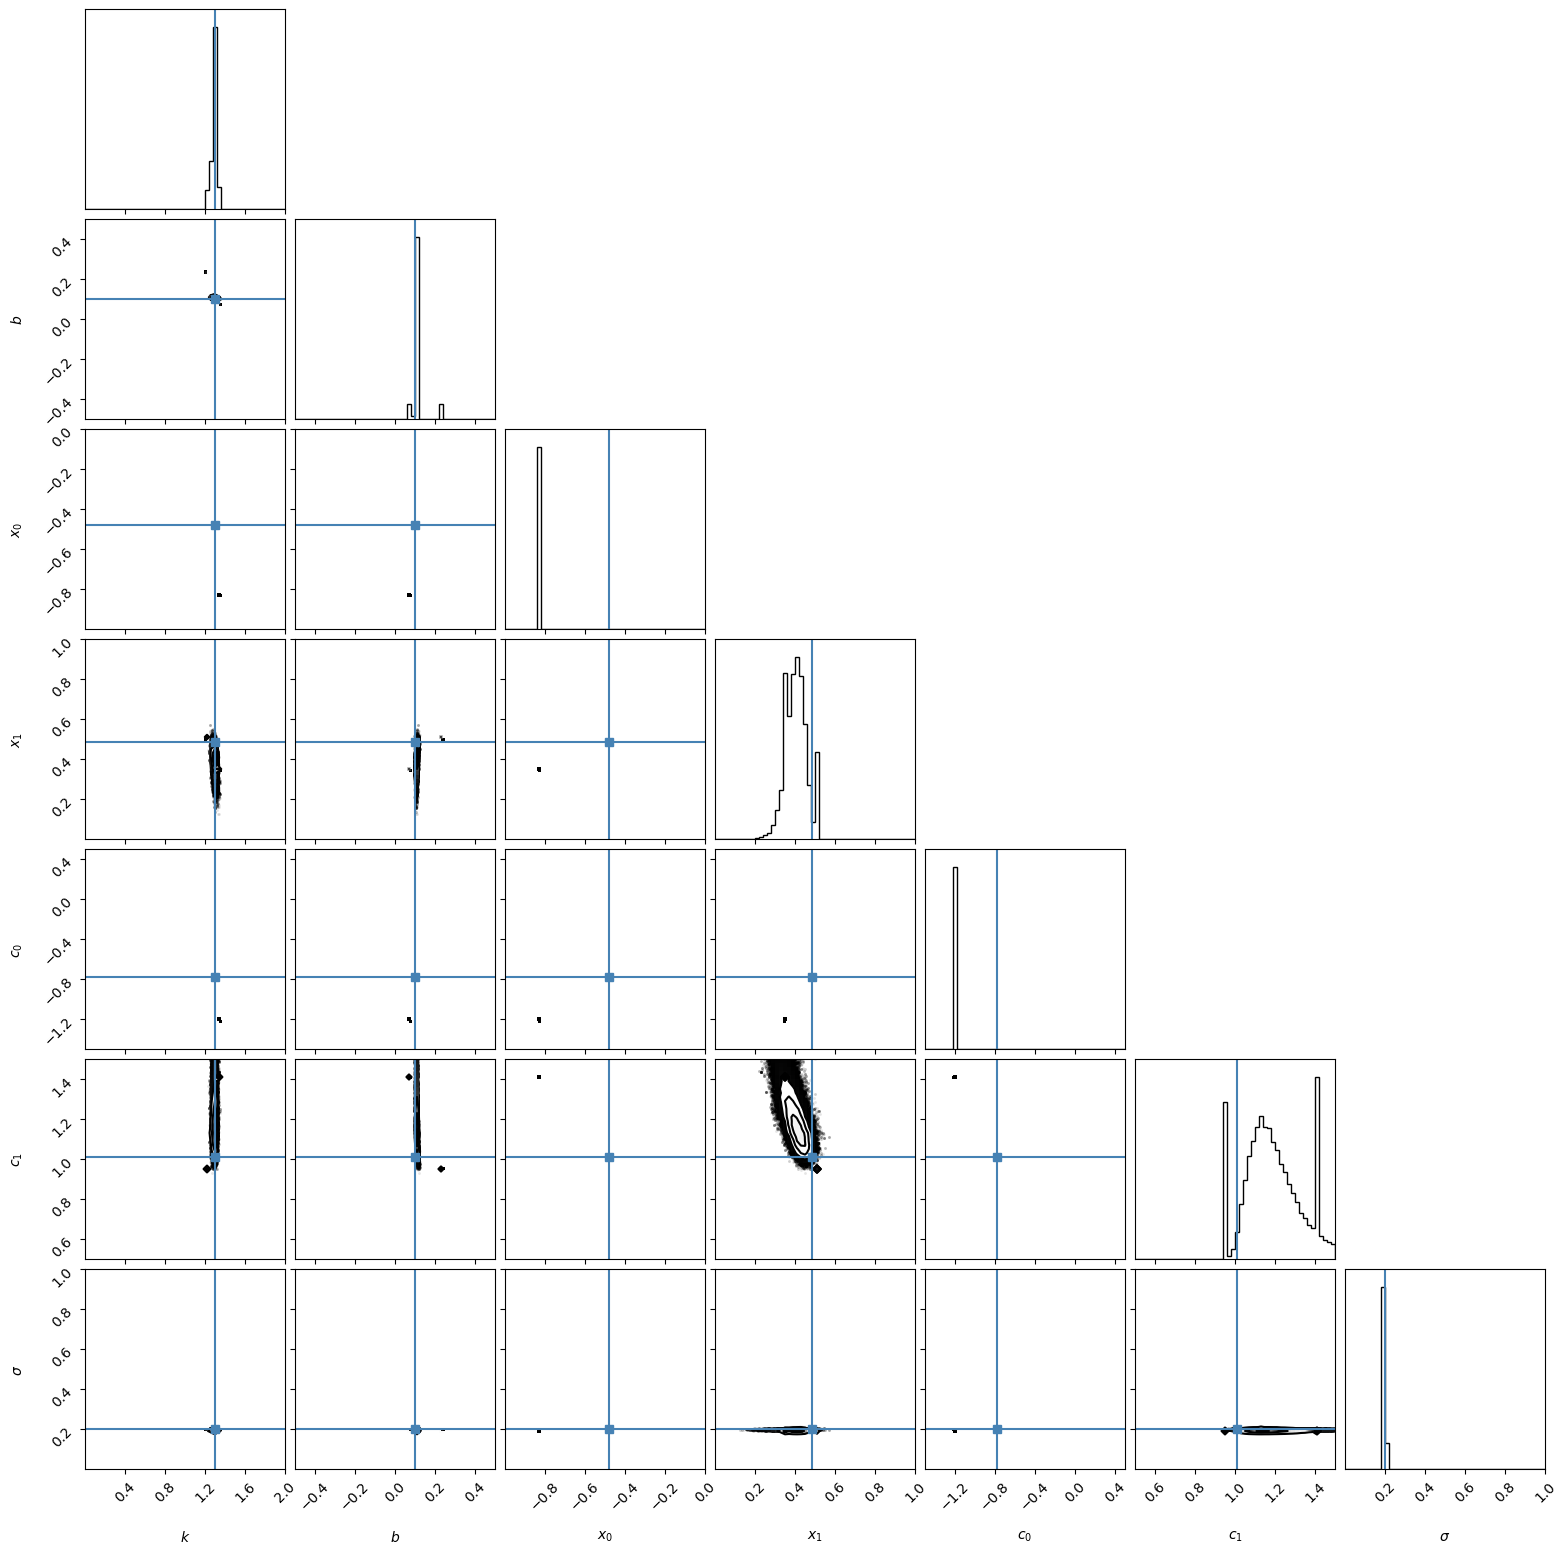

In [ ]:
fig = corner(
    sampler.get_chain(flat=True, discard=5000),
    truths=[k, b, x0, x1, c0, c1, sig],
    labels=["$k$", "$b$", "$x_0$", "$x_1$", "$c_0$", "$c_1$", "$\sigma$"],
    range=[(0, 2), (-0.5, 0.5), (-1, 0), (0, 1), (-1.5, 0.5), (0.5, 1.5),
           (0, 1)],
    bins=50,
    # plot_datapoints=False,
    plot_density=True,
)

## Compare

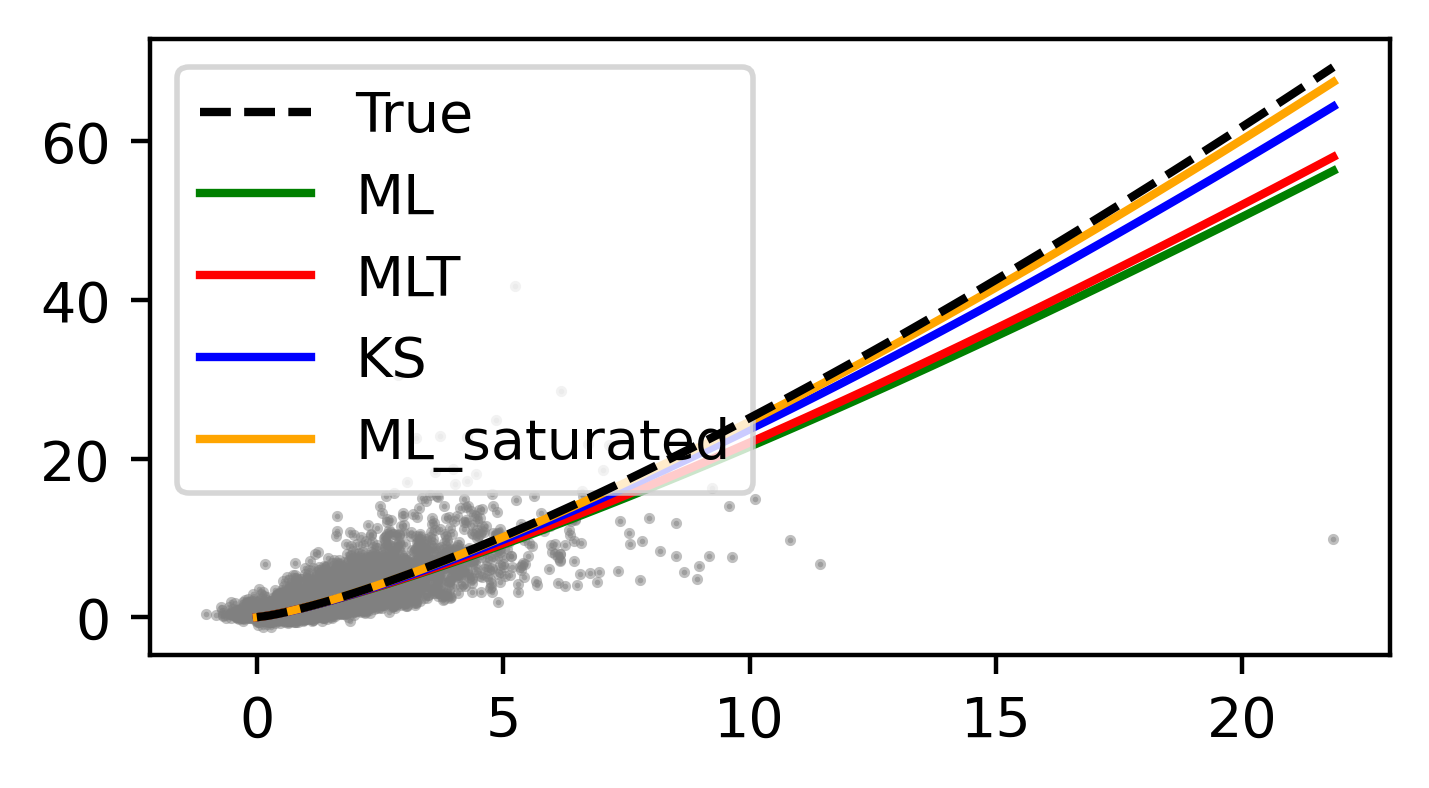

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])
# yy_ML_saturated = 10**saturated_linear_smooth(np.log10(xx),
#                                               *params_ml_saturated_c[:-1])
yy_ML_saturated = 10**(params_ml_saturated_c[0] * np.log10(xx) +
                       params_ml_saturated_c[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')
plt.plot(xx, yy_ML_saturated, color='orange', label='ML_saturated')

plt.legend()